In [2]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
else:
    print("GPU not detected")

PyTorch version: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4
CUDA version: 12.8


In [3]:
import os

print("Kaggle input datasets:")
for item in os.listdir("/kaggle/input"):
    print(item)

Kaggle input datasets:
datasets


In [4]:
import os

DATASET_PATH = "/kaggle/input/datasets/nih-chest-xrays/data"

print("Dataset path:", DATASET_PATH)
print("\nFiles/Folders:")

for item in os.listdir(DATASET_PATH):
    print(item)

Dataset path: /kaggle/input/datasets/nih-chest-xrays/data

Files/Folders:
images_003
images_012
LOG_CHESTXRAY.pdf
README_CHESTXRAY.pdf
BBox_List_2017.csv
images_009
images_008
images_007
test_list.txt
images_010
ARXIV_V5_CHESTXRAY.pdf
images_002
images_011
Data_Entry_2017.csv
images_001
train_val_list.txt
images_005
FAQ_CHESTXRAY.pdf
images_004
images_006


In [5]:
import pandas as pd
import os


DATASET_PATH = "/kaggle/input/datasets/nih-chest-xrays/data"

# Load metadata
df = pd.read_csv(os.path.join(DATASET_PATH, "Data_Entry_2017.csv"))

print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

# Load official train/test lists
with open(os.path.join(DATASET_PATH, "train_val_list.txt"), "r") as f:
    train_val_list = [x.strip() for x in f.readlines()]

with open(os.path.join(DATASET_PATH, "test_list.txt"), "r") as f:
    test_list = [x.strip() for x in f.readlines()]

print("\nOfficial train/val images:", len(train_val_list))
print("Official test images:", len(test_list))

print("\nFirst 5 train/val images:")
print(train_val_list[:5])

print("\nFirst 5 test images:")
print(test_list[:5])


Dataset Shape: (112120, 12)

Columns:
['Image Index', 'Finding Labels', 'Follow-up #', 'Patient ID', 'Patient Age', 'Patient Gender', 'View Position', 'OriginalImage[Width', 'Height]', 'OriginalImagePixelSpacing[x', 'y]', 'Unnamed: 11']

Official train/val images: 86524
Official test images: 25596

First 5 train/val images:
['00000001_000.png', '00000001_001.png', '00000001_002.png', '00000002_000.png', '00000004_000.png']

First 5 test images:
['00000003_000.png', '00000003_001.png', '00000003_002.png', '00000003_003.png', '00000003_004.png']


In [6]:
from sklearn.model_selection import GroupShuffleSplit
df = pd.read_csv(
    os.path.join(DATASET_PATH, "Data_Entry_2017.csv")
)

In [7]:
DISEASES = [
    "Atelectasis",
    "Cardiomegaly",
    "Consolidation",
    "Edema",
    "Effusion",
    "Emphysema",
    "Fibrosis",
    "Hernia",
    "Infiltration",
    "Mass",
    "Nodule",
    "Pleural_Thickening",
    "Pneumonia",
    "Pneumothorax"
]

In [8]:
with open(os.path.join(DATASET_PATH, "train_val_list.txt"), "r") as f:
    train_val_list = [x.strip() for x in f.readlines()]

with open(os.path.join(DATASET_PATH, "test_list.txt"), "r") as f:
    test_list = [x.strip() for x in f.readlines()]

In [9]:
image_to_path = {}

for folder in [f"images_{i:03d}" for i in range(1, 13)]:

    folder_path = os.path.join(DATASET_PATH, folder)

    # Some Kaggle versions have images inside an "images" folder
    possible_paths = [
        folder_path,
        os.path.join(folder_path, "images")
    ]

    for path in possible_paths:

        if not os.path.exists(path):
            continue

        for file in os.listdir(path):

            if file.endswith(".png"):
                image_to_path[file] = os.path.join(path, file)

print("Images indexed:", len(image_to_path))

Images indexed: 112120


In [10]:
train_val_available = [
    x for x in train_val_list
    if x in image_to_path
]

test_available = [
    x for x in test_list
    if x in image_to_path
]

print("Available train/val images:", len(train_val_available))
print("Available test images:", len(test_available))


Available train/val images: 86524
Available test images: 25596


In [11]:
train_val_df = df[df["Image Index"].isin(train_val_available)].copy()
test_df = df[df["Image Index"].isin(test_available)].copy()

# Add image paths
train_val_df["image_path"] = train_val_df["Image Index"].map(image_to_path)
test_df["image_path"] = test_df["Image Index"].map(image_to_path)

In [12]:
for disease in DISEASES:

    train_val_df[disease] = train_val_df["Finding Labels"].apply(
        lambda x: int(disease in x.split("|"))
    )

    test_df[disease] = test_df["Finding Labels"].apply(
        lambda x: int(disease in x.split("|"))
    )


In [13]:
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.10,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(
        train_val_df,
        groups=train_val_df["Patient ID"]
    )
)

train_df = train_val_df.iloc[train_idx].copy()
val_df = train_val_df.iloc[val_idx].copy()

In [14]:
train_patients = set(train_df["Patient ID"])
val_patients = set(val_df["Patient ID"])
test_patients = set(test_df["Patient ID"])

print("\n========== SPLIT RESULTS ==========")

print("Train images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))

print("\nTrain patients:", len(train_patients))
print("Validation patients:", len(val_patients))
print("Test patients:", len(test_patients))

print("\nPatient overlap:")

print(
    "Train ↔ Validation:",
    len(train_patients & val_patients)
)

print(
    "Train ↔ Test:",
    len(train_patients & test_patients)
)

print(
    "Validation ↔ Test:",
    len(val_patients & test_patients)
)


========== SPLIT RESULTS ==========
Train images: 77988
Validation images: 8536
Test images: 25596

Train patients: 25207
Validation patients: 2801
Test patients: 2797

Patient overlap:
Train ↔ Validation: 0
Train ↔ Test: 0
Validation ↔ Test: 0


In [15]:
print("\n========== DISEASE COUNTS ==========")

for disease in DISEASES:

    print(
        f"{disease:22s} "
        f"Train: {train_df[disease].sum():5d} | "
        f"Val: {val_df[disease].sum():5d} | "
        f"Test: {test_df[disease].sum():5d}"
    )


========== DISEASE COUNTS ==========
Atelectasis            Train:  7405 | Val:   875 | Test:  3279
Cardiomegaly           Train:  1549 | Val:   158 | Test:  1069
Consolidation          Train:  2584 | Val:   268 | Test:  1815
Edema                  Train:  1253 | Val:   125 | Test:   925
Effusion               Train:  7852 | Val:   807 | Test:  4658
Emphysema              Train:  1317 | Val:   106 | Test:  1093
Fibrosis               Train:  1111 | Val:   140 | Test:   435
Hernia                 Train:   122 | Val:    19 | Test:    86
Infiltration           Train: 12480 | Val:  1302 | Test:  6112
Mass                   Train:  3646 | Val:   388 | Test:  1748
Nodule                 Train:  4247 | Val:   461 | Test:  1623
Pleural_Thickening     Train:  1997 | Val:   245 | Test:  1143
Pneumonia              Train:   782 | Val:    94 | Test:   555
Pneumothorax           Train:  2394 | Val:   243 | Test:  2665


In [16]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

In [17]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [18]:
class ChestXrayDataset(Dataset):

    def __init__(self, dataframe, diseases, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.diseases = diseases
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        row = self.dataframe.iloc[idx]

        image_path = row["image_path"]

        # Open image
        image = Image.open(image_path).convert("RGB")

        # Apply transformations
        if self.transform:
            image = self.transform(image)

        # Get 14 labels
        labels = torch.tensor(
            row[self.diseases].values.astype("float32")
        )

        return image, labels

In [19]:
train_dataset = ChestXrayDataset(
    train_df,
    DISEASES,
    transform=transform
)

val_dataset = ChestXrayDataset(
    val_df,
    DISEASES,
    transform=transform
)

test_dataset = ChestXrayDataset(
    test_df,
    DISEASES,
    transform=transform
)


In [20]:
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

In [21]:
images, labels = next(iter(train_loader))

print("Train dataset size:", len(train_dataset))
print("Validation dataset size:", len(val_dataset))
print("Test dataset size:", len(test_dataset))

print("\nImage batch shape:", images.shape)
print("Label batch shape:", labels.shape)

print("\nImage dtype:", images.dtype)
print("Label dtype:", labels.dtype)

print("\nDevice available:", torch.cuda.is_available())

if torch.cuda.is_available():
     print("GPU:", torch.cuda.get_device_name(0))

Train dataset size: 77988
Validation dataset size: 8536
Test dataset size: 25596

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32, 14])

Image dtype: torch.float32
Label dtype: torch.float32

Device available: True
GPU: Tesla T4


In [22]:
import torch
import torch.nn as nn
from torchvision import models


In [23]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cuda


In [24]:
weights = models.DenseNet121_Weights.DEFAULT

model = models.densenet121(weights=weights)

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 230MB/s]


In [25]:
import torch
import torchvision

print(torch.__version__)
print(torchvision.__version__)
print(torch.cuda.is_available())

2.11.0+cu128
0.26.0+cu128
True


In [26]:
import os

cache_path = "/root/.cache/torch/hub/checkpoints"

print("Cached files:")

if os.path.exists(cache_path):
    print(os.listdir(cache_path))
else:
    print("Cache folder does not exist")

Cached files:
['densenet121-a639ec97.pth']


In [27]:
import urllib.request

url = "https://download.pytorch.org/models/densenet121-a639ec97.pth"

try:
    response = urllib.request.urlopen(url, timeout=20)
    print("Internet connection: OK")
    print("Status:", response.status)
except Exception as e:
    print("Internet connection failed:")
    print(e)

Internet connection: OK
Status: 200


In [28]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if "densenet" in file.lower():
            print(os.path.join(root, file))

In [29]:
import torch
import torch.nn as nn
from torchvision import models

device = torch.device("cuda")

model = models.densenet121(weights=None)

model.classifier = nn.Linear(
    model.classifier.in_features,
    14
)

model = model.to(device)

images, labels = next(iter(train_loader))
images = images.to(device)

with torch.no_grad():
    outputs = model(images)

print("Input :", images.shape)
print("Output:", outputs.shape)
print("GPU   :", torch.cuda.get_device_name(0))

Input : torch.Size([32, 3, 224, 224])
Output: torch.Size([32, 14])
GPU   : Tesla T4


In [30]:
import torch

# Number of positive samples for each disease
positive_counts = torch.tensor(
    [train_df[disease].sum() for disease in DISEASES],
    dtype=torch.float32
)

# Total training samples
total_samples = len(train_df)

# Calculate positive-class weights
pos_weight = (total_samples - positive_counts) / positive_counts

print("Disease                  Positive Samples    Pos Weight")
print("-" * 55)

for disease, count, weight in zip(
    DISEASES,
    positive_counts,
    pos_weight
):
    print(f"{disease:22s} {int(count):8d}        {weight:.2f}")

Disease                  Positive Samples    Pos Weight
-------------------------------------------------------
Atelectasis                7405        9.53
Cardiomegaly               1549        49.35
Consolidation              2584        29.18
Edema                      1253        61.24
Effusion                   7852        8.93
Emphysema                  1317        58.22
Fibrosis                   1111        69.20
Hernia                      122        638.25
Infiltration              12480        5.25
Mass                       3646        20.39
Nodule                     4247        17.36
Pleural_Thickening         1997        38.05
Pneumonia                   782        98.73
Pneumothorax               2394        31.58


In [31]:
import torch
import torch.nn as nn
from torchvision import models


In [32]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("GPU:", torch.cuda.get_device_name(0))


Device: cuda
GPU: Tesla T4


In [33]:
model = models.densenet121(weights=None)

model.classifier = nn.Linear(
    model.classifier.in_features,
    len(DISEASES)
)

model = model.to(device)


In [34]:
positive_counts = torch.tensor(
    [train_df[disease].sum() for disease in DISEASES],
    dtype=torch.float32
)

total_samples = len(train_df)

pos_weight = (
    (total_samples - positive_counts)
    / positive_counts
)


In [35]:
MAX_POS_WEIGHT = 50.0

pos_weight = torch.clamp(
    pos_weight,
    max=MAX_POS_WEIGHT
)

pos_weight = pos_weight.to(device)


In [36]:
criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)


In [37]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)


In [38]:
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=1
)


In [39]:
print("\nTraining configuration")
print("----------------------")

print("Classes:", len(DISEASES))
print("Learning rate:", 1e-4)
print("Weight decay:", 1e-4)
print("Max pos_weight:", MAX_POS_WEIGHT)

print("\nFinal pos_weights:")

for disease, weight in zip(DISEASES, pos_weight):
    print(f"{disease:22s}: {weight.item():.2f}")


Training configuration
----------------------
Classes: 14
Learning rate: 0.0001
Weight decay: 0.0001
Max pos_weight: 50.0

Final pos_weights:
Atelectasis           : 9.53
Cardiomegaly          : 49.35
Consolidation         : 29.18
Edema                 : 50.00
Effusion              : 8.93
Emphysema             : 50.00
Fibrosis              : 50.00
Hernia                : 50.00
Infiltration          : 5.25
Mass                  : 20.39
Nodule                : 17.36
Pleural_Thickening    : 38.05
Pneumonia             : 50.00
Pneumothorax          : 31.58


In [40]:
import time

In [41]:
model.train()

smoke_test_batches = 100

running_loss = 0.0
start_time = time.time()

for batch_idx, (images, labels) in enumerate(train_loader):

    if batch_idx >= smoke_test_batches:
        break

    images = images.to(device, non_blocking=True)
    labels = labels.to(device, non_blocking=True)

    optimizer.zero_grad(set_to_none=True)

    outputs = model(images)

    loss = criterion(outputs, labels)

    loss.backward()

    optimizer.step()

    running_loss += loss.item()

    if (batch_idx + 1) % 10 == 0:
        print(
            f"Batch [{batch_idx + 1}/{smoke_test_batches}] "
            f"Loss: {loss.item():.4f}"
        )

avg_loss = running_loss / smoke_test_batches
elapsed = time.time() - start_time

print("\n========== SMOKE TEST ==========")
print("Batches:", smoke_test_batches)
print("Average loss:", round(avg_loss, 4))
print("Time:", round(elapsed, 2), "seconds")
print("Time per batch:", round(elapsed / smoke_test_batches, 3), "seconds")

print("\nGPU memory:")
print(
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB allocated"
)
print(
    round(torch.cuda.max_memory_allocated() / 1024**3, 2),
    "GB peak"
)

Batch [10/100] Loss: 1.1595
Batch [20/100] Loss: 1.0810
Batch [30/100] Loss: 1.2606
Batch [40/100] Loss: 1.3969
Batch [50/100] Loss: 1.1764
Batch [60/100] Loss: 1.1668
Batch [70/100] Loss: 1.2060
Batch [80/100] Loss: 0.9615
Batch [90/100] Loss: 1.2227
Batch [100/100] Loss: 1.3168

========== SMOKE TEST ==========
Batches: 100
Average loss: 1.1867
Time: 53.6 seconds
Time per batch: 0.536 seconds

GPU memory:
0.12 GB allocated
4.03 GB peak


In [42]:

# Reset DenseNet121 before real training
model = models.densenet121(weights=None)

model.classifier = nn.Linear(
    model.classifier.in_features,
    len(DISEASES)
)

model = model.to(device)

# Reset loss
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

# Reset optimizer
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

# Reset scheduler
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=1
)

print("Model reset successfully")
print("Device:", device)
print("Classes:", len(DISEASES))


Model reset successfully
Device: cuda
Classes: 14


In [43]:
model.train()

running_loss = 0.0

for batch_idx, (images, labels) in enumerate(train_loader):

    images = images.to(device, non_blocking=True)
    labels = labels.to(device, non_blocking=True)

    optimizer.zero_grad()

    outputs = model(images)

    loss = criterion(outputs, labels)

    loss.backward()
    optimizer.step()

    running_loss += loss.item()

    if (batch_idx + 1) % 100 == 0:
        print(
            f"Batch [{batch_idx + 1}/{len(train_loader)}] "
            f"Loss: {loss.item():.4f}"
        )

train_loss = running_loss / len(train_loader)

print("\n========== TRAINING ==========")
print(f"Train Loss: {train_loss:.4f}")

Batch [100/2438] Loss: 1.6108
Batch [200/2438] Loss: 1.2133
Batch [300/2438] Loss: 1.0216
Batch [400/2438] Loss: 0.7449
Batch [500/2438] Loss: 0.8532
Batch [600/2438] Loss: 1.4104
Batch [700/2438] Loss: 1.1592
Batch [800/2438] Loss: 1.0732
Batch [900/2438] Loss: 1.0771
Batch [1000/2438] Loss: 1.2575
Batch [1100/2438] Loss: 1.0339
Batch [1200/2438] Loss: 1.2785
Batch [1300/2438] Loss: 1.2885
Batch [1400/2438] Loss: 0.9679
Batch [1500/2438] Loss: 1.2575
Batch [1600/2438] Loss: 0.7901
Batch [1700/2438] Loss: 1.1511
Batch [1800/2438] Loss: 1.1174
Batch [1900/2438] Loss: 1.0190
Batch [2000/2438] Loss: 1.6850
Batch [2100/2438] Loss: 0.9465
Batch [2200/2438] Loss: 1.1412
Batch [2300/2438] Loss: 0.9006
Batch [2400/2438] Loss: 0.8945

========== TRAINING ==========
Train Loss: 1.0892


In [44]:
model.eval()

val_loss = 0.0

all_val_labels = []
all_val_probs = []

with torch.no_grad():

    for batch_idx, (images, labels) in enumerate(val_loader):

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        outputs = model(images)

        loss = criterion(outputs, labels)
        val_loss += loss.item()

        # Convert logits to probabilities
        probs = torch.sigmoid(outputs)

        all_val_labels.append(labels.cpu())
        all_val_probs.append(probs.cpu())

        if (batch_idx + 1) % 100 == 0:
            print(
                f"Validation Batch [{batch_idx + 1}/{len(val_loader)}]"
            )

val_loss = val_loss / len(val_loader)

# Combine all batches
all_val_labels = torch.cat(all_val_labels).numpy()
all_val_probs = torch.cat(all_val_probs).numpy()

print("\n========== VALIDATION ==========")
print(f"Validation Loss: {val_loss:.4f}")
print("Labels shape:", all_val_labels.shape)
print("Predictions shape:", all_val_probs.shape)

Validation Batch [100/267]
Validation Batch [200/267]

========== VALIDATION ==========
Validation Loss: 1.0555
Labels shape: (8536, 14)
Predictions shape: (8536, 14)


In [45]:
# Calculate AUROC for each disease

from sklearn.metrics import roc_auc_score

auc_scores = {}

for i, disease in enumerate(DISEASES):

    try:
        auc = roc_auc_score(
            all_val_labels[:, i],
            all_val_probs[:, i]
        )

        auc_scores[disease] = auc

    except ValueError:
        auc_scores[disease] = float("nan")


print("========== VALIDATION AUROC ==========\n")

for disease, auc in auc_scores.items():
    print(f"{disease:20s}: {auc:.4f}")


# Macro AUROC
valid_auc_scores = [
    score for score in auc_scores.values()
    if not torch.isnan(torch.tensor(score))
]

macro_auc = sum(valid_auc_scores) / len(valid_auc_scores)

print("\n======================================")
print(f"Macro AUROC: {macro_auc:.4f}")


========== VALIDATION AUROC ==========

Atelectasis         : 0.7219
Cardiomegaly        : 0.7282
Consolidation       : 0.7787
Edema               : 0.8771
Effusion            : 0.8209
Emphysema           : 0.6996
Fibrosis            : 0.7223
Hernia              : 0.7113
Infiltration        : 0.6707
Mass                : 0.6779
Nodule              : 0.5962
Pleural_Thickening  : 0.6751
Pneumonia           : 0.6521
Pneumothorax        : 0.7267

Macro AUROC: 0.7185


In [46]:
# Save Epoch 1 checkpoint

checkpoint = {
    "epoch": 1,
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "val_loss": val_loss,
    "macro_auc": macro_auc,
    "diseases": DISEASES
}

torch.save(checkpoint, "densenet121_epoch1.pth")

print("Checkpoint saved successfully!")
print(f"Macro AUROC: {macro_auc:.4f}")

Checkpoint saved successfully!
Macro AUROC: 0.7185


In [47]:
model.train()

running_loss = 0.0

for batch_idx, (images, labels) in enumerate(train_loader):

    images = images.to(device, non_blocking=True)
    labels = labels.to(device, non_blocking=True)

    optimizer.zero_grad()

    outputs = model(images)

    loss = criterion(outputs, labels)

    loss.backward()
    optimizer.step()

    running_loss += loss.item()

    if (batch_idx + 1) % 100 == 0:
        print(
            f"Epoch 2 | Batch [{batch_idx + 1}/{len(train_loader)}] "
            f"Loss: {loss.item():.4f}"
        )

train_loss_epoch2 = running_loss / len(train_loader)

print("\n========== EPOCH 2 TRAINING ==========")
print(f"Train Loss: {train_loss_epoch2:.4f}")

Epoch 2 | Batch [100/2438] Loss: 0.8612
Epoch 2 | Batch [200/2438] Loss: 0.8170
Epoch 2 | Batch [300/2438] Loss: 0.9750
Epoch 2 | Batch [400/2438] Loss: 0.8268
Epoch 2 | Batch [500/2438] Loss: 0.9792
Epoch 2 | Batch [600/2438] Loss: 0.8964
Epoch 2 | Batch [700/2438] Loss: 0.7748
Epoch 2 | Batch [800/2438] Loss: 1.0283
Epoch 2 | Batch [900/2438] Loss: 0.9038
Epoch 2 | Batch [1000/2438] Loss: 1.1142
Epoch 2 | Batch [1100/2438] Loss: 1.5162
Epoch 2 | Batch [1200/2438] Loss: 0.8072
Epoch 2 | Batch [1300/2438] Loss: 0.6572
Epoch 2 | Batch [1400/2438] Loss: 0.9450
Epoch 2 | Batch [1500/2438] Loss: 1.2740
Epoch 2 | Batch [1600/2438] Loss: 1.5927
Epoch 2 | Batch [1700/2438] Loss: 0.6960
Epoch 2 | Batch [1800/2438] Loss: 1.0714
Epoch 2 | Batch [1900/2438] Loss: 0.9864
Epoch 2 | Batch [2000/2438] Loss: 0.8357
Epoch 2 | Batch [2100/2438] Loss: 0.8624
Epoch 2 | Batch [2200/2438] Loss: 0.9225
Epoch 2 | Batch [2300/2438] Loss: 0.8425
Epoch 2 | Batch [2400/2438] Loss: 1.0975

========== EPOCH 2 TRAIN

In [48]:
model.eval()

val_loss_epoch2 = 0.0

all_val_labels_epoch2 = []
all_val_probs_epoch2 = []

with torch.no_grad():

    for batch_idx, (images, labels) in enumerate(val_loader):

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        outputs = model(images)

        loss = criterion(outputs, labels)
        val_loss_epoch2 += loss.item()

        probs = torch.sigmoid(outputs)

        all_val_labels_epoch2.append(labels.cpu())
        all_val_probs_epoch2.append(probs.cpu())

        if (batch_idx + 1) % 100 == 0:
            print(
                f"Epoch 2 Validation [{batch_idx + 1}/{len(val_loader)}]"
            )

val_loss_epoch2 /= len(val_loader)

all_val_labels_epoch2 = torch.cat(all_val_labels_epoch2).numpy()
all_val_probs_epoch2 = torch.cat(all_val_probs_epoch2).numpy()

print("\n========== EPOCH 2 VALIDATION ==========")
print(f"Validation Loss: {val_loss_epoch2:.4f}")

Epoch 2 Validation [100/267]
Epoch 2 Validation [200/267]

========== EPOCH 2 VALIDATION ==========
Validation Loss: 1.0053


In [49]:
auc_scores_epoch2 = {}

for i, disease in enumerate(DISEASES):

    try:
        auc = roc_auc_score(
            all_val_labels_epoch2[:, i],
            all_val_probs_epoch2[:, i]
        )

        auc_scores_epoch2[disease] = auc

    except ValueError:
        auc_scores_epoch2[disease] = float("nan")


print("\n========== EPOCH 2 AUROC ==========\n")

for disease, auc in auc_scores_epoch2.items():
    print(f"{disease:20s}: {auc:.4f}")


valid_auc_scores = [
    score for score in auc_scores_epoch2.values()
    if not torch.isnan(torch.tensor(score))
]

macro_auc_epoch2 = sum(valid_auc_scores) / len(valid_auc_scores)

print("\n====================================")
print(f"Macro AUROC: {macro_auc_epoch2:.4f}")


========== EPOCH 2 AUROC ==========

Atelectasis         : 0.7335
Cardiomegaly        : 0.8305
Consolidation       : 0.7616
Edema               : 0.8848
Effusion            : 0.8405
Emphysema           : 0.7144
Fibrosis            : 0.7488
Hernia              : 0.7571
Infiltration        : 0.6708
Mass                : 0.7198
Nodule              : 0.5924
Pleural_Thickening  : 0.7296
Pneumonia           : 0.6586
Pneumothorax        : 0.7202

Macro AUROC: 0.7402


In [50]:
best_macro_auc = macro_auc_epoch2

checkpoint = {
    "epoch": 2,
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "val_loss": val_loss_epoch2,
    "macro_auc": best_macro_auc,
    "diseases": DISEASES
}

torch.save(checkpoint, "best_densenet121.pth")

print("========== BEST MODEL SAVED ==========")
print(f"Epoch: 2")
print(f"Macro AUROC: {best_macro_auc:.4f}")
print("File: best_densenet121.pth")

========== BEST MODEL SAVED ==========
Epoch: 2
Macro AUROC: 0.7402
File: best_densenet121.pth


In [57]:
scheduler.step(macro_auc_epoch2)

print("Scheduler updated")
print("Current learning rate:", optimizer.param_groups[0]["lr"])

Scheduler updated
Current learning rate: 5e-05


In [58]:
model.train()

running_loss = 0.0

for batch_idx, (images, labels) in enumerate(train_loader):

    images = images.to(device, non_blocking=True)
    labels = labels.to(device, non_blocking=True)

    optimizer.zero_grad()

    outputs = model(images)

    loss = criterion(outputs, labels)

    loss.backward()
    optimizer.step()

    running_loss += loss.item()

    if (batch_idx + 1) % 100 == 0:
        print(
            f"Epoch 3 | Batch [{batch_idx + 1}/{len(train_loader)}] "
            f"Loss: {loss.item():.4f}"
        )

train_loss_epoch3 = running_loss / len(train_loader)

print("\n========== EPOCH 3 TRAINING ==========")
print(f"Train Loss: {train_loss_epoch3:.4f}")

Epoch 3 | Batch [100/2438] Loss: 0.9412
Epoch 3 | Batch [200/2438] Loss: 0.7271
Epoch 3 | Batch [300/2438] Loss: 0.8542
Epoch 3 | Batch [400/2438] Loss: 0.6537
Epoch 3 | Batch [500/2438] Loss: 0.9026
Epoch 3 | Batch [600/2438] Loss: 0.8244
Epoch 3 | Batch [700/2438] Loss: 1.0445
Epoch 3 | Batch [800/2438] Loss: 1.2513
Epoch 3 | Batch [900/2438] Loss: 0.9423
Epoch 3 | Batch [1000/2438] Loss: 1.2264
Epoch 3 | Batch [1100/2438] Loss: 1.2156
Epoch 3 | Batch [1200/2438] Loss: 0.9331
Epoch 3 | Batch [1300/2438] Loss: 1.3559
Epoch 3 | Batch [1400/2438] Loss: 1.3427
Epoch 3 | Batch [1500/2438] Loss: 0.9884
Epoch 3 | Batch [1600/2438] Loss: 0.8944
Epoch 3 | Batch [1700/2438] Loss: 1.0429
Epoch 3 | Batch [1800/2438] Loss: 0.9484
Epoch 3 | Batch [1900/2438] Loss: 0.9344
Epoch 3 | Batch [2000/2438] Loss: 0.7466
Epoch 3 | Batch [2100/2438] Loss: 1.1089
Epoch 3 | Batch [2200/2438] Loss: 0.6980
Epoch 3 | Batch [2300/2438] Loss: 1.1181
Epoch 3 | Batch [2400/2438] Loss: 0.8875

========== EPOCH 3 TRAIN

In [59]:
model.eval()

val_loss_epoch3 = 0.0

all_val_labels_epoch3 = []
all_val_probs_epoch3 = []

with torch.no_grad():

    for batch_idx, (images, labels) in enumerate(val_loader):

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        outputs = model(images)

        loss = criterion(outputs, labels)
        val_loss_epoch3 += loss.item()

        probs = torch.sigmoid(outputs)

        all_val_labels_epoch3.append(labels.cpu())
        all_val_probs_epoch3.append(probs.cpu())

        if (batch_idx + 1) % 100 == 0:
            print(
                f"Epoch 3 Validation [{batch_idx + 1}/{len(val_loader)}]"
            )

val_loss_epoch3 /= len(val_loader)

all_val_labels_epoch3 = torch.cat(all_val_labels_epoch3).numpy()
all_val_probs_epoch3 = torch.cat(all_val_probs_epoch3).numpy()

print("\n========== EPOCH 3 VALIDATION ==========")
print(f"Validation Loss: {val_loss_epoch3:.4f}")

Epoch 3 Validation [100/267]
Epoch 3 Validation [200/267]

========== EPOCH 3 VALIDATION ==========
Validation Loss: 0.9439


In [60]:
auc_scores_epoch3 = {}

for i, disease in enumerate(DISEASES):

    auc = roc_auc_score(
        all_val_labels_epoch3[:, i],
        all_val_probs_epoch3[:, i]
    )

    auc_scores_epoch3[disease] = auc

print("\n========== EPOCH 3 AUROC ==========\n")

for disease, auc in auc_scores_epoch3.items():
    print(f"{disease:20s}: {auc:.4f}")

macro_auc_epoch3 = sum(auc_scores_epoch3.values()) / len(auc_scores_epoch3)

print("\n====================================")
print(f"Macro AUROC: {macro_auc_epoch3:.4f}")


========== EPOCH 3 AUROC ==========

Atelectasis         : 0.7744
Cardiomegaly        : 0.8907
Consolidation       : 0.7967
Edema               : 0.9005
Effusion            : 0.8739
Emphysema           : 0.7695
Fibrosis            : 0.7818
Hernia              : 0.8302
Infiltration        : 0.6963
Mass                : 0.7863
Nodule              : 0.6514
Pleural_Thickening  : 0.7637
Pneumonia           : 0.6807
Pneumothorax        : 0.8105

Macro AUROC: 0.7862


In [61]:
best_macro_auc = macro_auc_epoch3

checkpoint = {
    "epoch": 3,
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "val_loss": val_loss_epoch3,
    "macro_auc": best_macro_auc,
    "diseases": DISEASES
}

torch.save(checkpoint, "best_densenet121.pth")

print("========== BEST MODEL UPDATED ==========")
print(f"Best Epoch: 3")
print(f"Best Macro AUROC: {best_macro_auc:.4f}")
print("File: best_densenet121.pth")


========== BEST MODEL UPDATED ==========
Best Epoch: 3
Best Macro AUROC: 0.7862
File: best_densenet121.pth


In [62]:
scheduler.step(macro_auc_epoch3)

print("Scheduler updated")
print("Current learning rate:", optimizer.param_groups[0]["lr"])

Scheduler updated
Current learning rate: 5e-05


In [63]:
model.train()
running_loss = 0.0

for batch_idx, (images, labels) in enumerate(train_loader):
    images = images.to(device, non_blocking=True)
    labels = labels.to(device, non_blocking=True)

    optimizer.zero_grad()

    outputs = model(images)
    loss = criterion(outputs, labels)

    loss.backward()
    optimizer.step()

    running_loss += loss.item()

    if (batch_idx + 1) % 100 == 0:
        print(
            f"Epoch 4 | Batch [{batch_idx + 1}/{len(train_loader)}] "
            f"Loss: {loss.item():.4f}"
        )

train_loss_epoch4 = running_loss / len(train_loader)

print("\n========== EPOCH 4 TRAINING ==========")
print(f"Train Loss: {train_loss_epoch4:.4f}")

Epoch 4 | Batch [100/2438] Loss: 0.7778
Epoch 4 | Batch [200/2438] Loss: 0.8934
Epoch 4 | Batch [300/2438] Loss: 0.9800
Epoch 4 | Batch [400/2438] Loss: 0.8099
Epoch 4 | Batch [500/2438] Loss: 0.7893
Epoch 4 | Batch [600/2438] Loss: 0.8328
Epoch 4 | Batch [700/2438] Loss: 0.9443
Epoch 4 | Batch [800/2438] Loss: 0.8215
Epoch 4 | Batch [900/2438] Loss: 1.1754
Epoch 4 | Batch [1000/2438] Loss: 0.8341
Epoch 4 | Batch [1100/2438] Loss: 0.7898
Epoch 4 | Batch [1200/2438] Loss: 0.8556
Epoch 4 | Batch [1300/2438] Loss: 1.0107
Epoch 4 | Batch [1400/2438] Loss: 0.6590
Epoch 4 | Batch [1500/2438] Loss: 1.2559
Epoch 4 | Batch [1600/2438] Loss: 0.6683
Epoch 4 | Batch [1700/2438] Loss: 0.8011
Epoch 4 | Batch [1800/2438] Loss: 0.9956
Epoch 4 | Batch [1900/2438] Loss: 1.0690
Epoch 4 | Batch [2000/2438] Loss: 0.9312
Epoch 4 | Batch [2100/2438] Loss: 0.7691
Epoch 4 | Batch [2200/2438] Loss: 0.9795
Epoch 4 | Batch [2300/2438] Loss: 0.9744
Epoch 4 | Batch [2400/2438] Loss: 0.6582

========== EPOCH 4 TRAIN

In [64]:
model.eval()

val_loss = 0.0
all_outputs = []
all_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        outputs = model(images)

        loss = criterion(outputs, labels)
        val_loss += loss.item()

        all_outputs.append(outputs.cpu())
        all_labels.append(labels.cpu())

val_loss_epoch4 = val_loss / len(val_loader)

all_outputs = torch.cat(all_outputs).numpy()
all_labels = torch.cat(all_labels).numpy()

print("========== EPOCH 4 VALIDATION ==========")
print(f"Validation Loss: {val_loss_epoch4:.4f}")
print(f"Prediction Shape: {all_outputs.shape}")

========== EPOCH 4 VALIDATION ==========
Validation Loss: 0.9747
Prediction Shape: (8536, 14)


In [68]:
import numpy as np

val_probs = 1 / (1 + np.exp(-all_outputs))

auc_scores = []

for i, disease in enumerate(DISEASES):
    auc = roc_auc_score(all_labels[:, i], val_probs[:, i])
    auc_scores.append(auc)
    print(f"{disease}: {auc:.4f}")

macro_auc_epoch4 = np.mean(auc_scores)

print("\n========== EPOCH 4 RESULTS ==========")
print(f"Macro AUROC: {macro_auc_epoch4:.4f}")

Atelectasis: 0.7636
Cardiomegaly: 0.8780
Consolidation: 0.7934
Edema: 0.8985
Effusion: 0.8709
Emphysema: 0.7694
Fibrosis: 0.7545
Hernia: 0.8371
Infiltration: 0.7057
Mass: 0.7852
Nodule: 0.6495
Pleural_Thickening: 0.7517
Pneumonia: 0.6615
Pneumothorax: 0.8059

========== EPOCH 4 RESULTS ==========
Macro AUROC: 0.7803


In [69]:
best_macro_auc = macro_auc_epoch4

checkpoint = {
    "epoch": 4,
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "val_loss": val_loss_epoch4,
    "macro_auc": best_macro_auc,
    "diseases": DISEASES
}

torch.save(checkpoint, "best_densenet121.pth")

print("========== BEST MODEL UPDATED ==========")
print(f"Best Epoch: 4")
print(f"Best Macro AUROC: {best_macro_auc:.4f}")
print("File: best_densenet121.pth")

========== BEST MODEL UPDATED ==========
Best Epoch: 4
Best Macro AUROC: 0.7803
File: best_densenet121.pth


In [70]:
scheduler.step(macro_auc_epoch4)

print("Scheduler updated")
print("Current learning rate:", optimizer.param_groups[0]["lr"])

Scheduler updated
Current learning rate: 5e-05


In [71]:
model.train()
running_loss = 0.0

for batch_idx, (images, labels) in enumerate(train_loader):
    images = images.to(device, non_blocking=True)
    labels = labels.to(device, non_blocking=True)

    optimizer.zero_grad()

    outputs = model(images)
    loss = criterion(outputs, labels)

    loss.backward()
    optimizer.step()

    running_loss += loss.item()

    if (batch_idx + 1) % 100 == 0:
        print(
            f"Epoch 5 | Batch [{batch_idx + 1}/{len(train_loader)}] "
            f"Loss: {loss.item():.4f}"
        )

train_loss_epoch5 = running_loss / len(train_loader)

print("\n========== EPOCH 5 TRAINING ==========")
print(f"Train Loss: {train_loss_epoch5:.4f}")

Epoch 5 | Batch [100/2438] Loss: 0.8226
Epoch 5 | Batch [200/2438] Loss: 0.9261
Epoch 5 | Batch [300/2438] Loss: 0.8826
Epoch 5 | Batch [400/2438] Loss: 1.0238
Epoch 5 | Batch [500/2438] Loss: 0.5763
Epoch 5 | Batch [600/2438] Loss: 0.5959
Epoch 5 | Batch [700/2438] Loss: 0.8605
Epoch 5 | Batch [800/2438] Loss: 1.0041
Epoch 5 | Batch [900/2438] Loss: 0.7529
Epoch 5 | Batch [1000/2438] Loss: 1.1157
Epoch 5 | Batch [1100/2438] Loss: 0.8862
Epoch 5 | Batch [1200/2438] Loss: 0.8273
Epoch 5 | Batch [1300/2438] Loss: 0.5485
Epoch 5 | Batch [1400/2438] Loss: 0.7930
Epoch 5 | Batch [1500/2438] Loss: 0.6252
Epoch 5 | Batch [1600/2438] Loss: 0.5967
Epoch 5 | Batch [1700/2438] Loss: 1.2304
Epoch 5 | Batch [1800/2438] Loss: 0.6862
Epoch 5 | Batch [1900/2438] Loss: 1.0385
Epoch 5 | Batch [2000/2438] Loss: 1.0712
Epoch 5 | Batch [2100/2438] Loss: 0.8525
Epoch 5 | Batch [2200/2438] Loss: 0.7161
Epoch 5 | Batch [2300/2438] Loss: 1.0692
Epoch 5 | Batch [2400/2438] Loss: 0.9929

========== EPOCH 5 TRAIN

In [72]:
model.eval()

val_loss = 0.0
all_outputs = []
all_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        outputs = model(images)

        loss = criterion(outputs, labels)
        val_loss += loss.item()

        all_outputs.append(outputs.cpu())
        all_labels.append(labels.cpu())

val_loss_epoch5 = val_loss / len(val_loader)

all_outputs = torch.cat(all_outputs).numpy()
all_labels = torch.cat(all_labels).numpy()

print("========== EPOCH 5 VALIDATION ==========")
print(f"Validation Loss: {val_loss_epoch5:.4f}")
print(f"Prediction Shape: {all_outputs.shape}")

========== EPOCH 5 VALIDATION ==========
Validation Loss: 0.9483
Prediction Shape: (8536, 14)


In [73]:
val_probs = 1 / (1 + np.exp(-all_outputs))

auc_scores = []

for i, disease in enumerate(DISEASES):
    auc = roc_auc_score(all_labels[:, i], val_probs[:, i])
    auc_scores.append(auc)
    print(f"{disease}: {auc:.4f}")

macro_auc_epoch5 = np.mean(auc_scores)

print("\n========== EPOCH 5 RESULTS ==========")
print(f"Macro AUROC: {macro_auc_epoch5:.4f}")

Atelectasis: 0.7701
Cardiomegaly: 0.8850
Consolidation: 0.7937
Edema: 0.9018
Effusion: 0.8735
Emphysema: 0.7768
Fibrosis: 0.7899
Hernia: 0.8284
Infiltration: 0.7057
Mass: 0.7889
Nodule: 0.6471
Pleural_Thickening: 0.7573
Pneumonia: 0.6784
Pneumothorax: 0.8071

========== EPOCH 5 RESULTS ==========
Macro AUROC: 0.7860


In [74]:
best_macro_auc = macro_auc_epoch5

checkpoint = {
    "epoch": 5,
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "val_loss": val_loss_epoch5,
    "macro_auc": best_macro_auc,
    "diseases": DISEASES
}

torch.save(checkpoint, "best_densenet121.pth")

print("========== FINAL BEST MODEL SAVED ==========")
print(f"Best Epoch: 5")
print(f"Best Macro AUROC: {best_macro_auc:.4f}")
print("File: best_densenet121.pth")

========== FINAL BEST MODEL SAVED ==========
Best Epoch: 5
Best Macro AUROC: 0.7860
File: best_densenet121.pth


In [76]:
checkpoint = torch.load(
    "best_densenet121.pth",
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

print("========== FINAL MODEL LOADED ==========")
print(f"Epoch: {checkpoint['epoch']}")
print(f"Validation Macro AUROC: {checkpoint['macro_auc']:.4f}")
print("Model ready for official test evaluation.")

========== FINAL MODEL LOADED ==========
Epoch: 5
Validation Macro AUROC: 0.7860
Model ready for official test evaluation.


In [77]:
model.eval()

test_loss = 0.0
test_outputs = []
test_labels = []

with torch.no_grad():
    for batch_idx, (images, labels) in enumerate(test_loader):

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        outputs = model(images)

        loss = criterion(outputs, labels)
        test_loss += loss.item()

        test_outputs.append(outputs.cpu())
        test_labels.append(labels.cpu())

        if (batch_idx + 1) % 100 == 0:
            print(
                f"Test Batch [{batch_idx + 1}/{len(test_loader)}]"
            )

test_loss = test_loss / len(test_loader)

test_outputs = torch.cat(test_outputs).numpy()
test_labels = torch.cat(test_labels).numpy()

print("\n========== OFFICIAL TEST SET ==========")
print(f"Test Loss: {test_loss:.4f}")
print(f"Prediction Shape: {test_outputs.shape}")
print(f"Label Shape: {test_labels.shape}")

Test Batch [100/800]
Test Batch [200/800]
Test Batch [300/800]
Test Batch [400/800]
Test Batch [500/800]
Test Batch [600/800]
Test Batch [700/800]
Test Batch [800/800]

========== OFFICIAL TEST SET ==========
Test Loss: 1.3797
Prediction Shape: (25596, 14)
Label Shape: (25596, 14)


In [78]:
test_probs = 1 / (1 + np.exp(-test_outputs))

test_auc_scores = []

for i, disease in enumerate(DISEASES):
    auc = roc_auc_score(test_labels[:, i], test_probs[:, i])
    test_auc_scores.append(auc)
    print(f"{disease}: {auc:.4f}")

test_macro_auc = np.mean(test_auc_scores)

print("\n========== FINAL TEST RESULTS ==========")
print(f"Test Macro AUROC: {test_macro_auc:.4f}")

Atelectasis: 0.7195
Cardiomegaly: 0.8635
Consolidation: 0.7104
Edema: 0.8192
Effusion: 0.7825
Emphysema: 0.7594
Fibrosis: 0.7483
Hernia: 0.8598
Infiltration: 0.6718
Mass: 0.7176
Nodule: 0.6414
Pleural_Thickening: 0.7212
Pneumonia: 0.6595
Pneumothorax: 0.7874

========== FINAL TEST RESULTS ==========
Test Macro AUROC: 0.7472


In [79]:
from sklearn.metrics import precision_score, recall_score, f1_score

test_pred_binary = (test_probs >= 0.5).astype(int)

precision_scores = precision_score(
    test_labels,
    test_pred_binary,
    average=None,
    zero_division=0
)

recall_scores = recall_score(
    test_labels,
    test_pred_binary,
    average=None,
    zero_division=0
)

f1_scores = f1_score(
    test_labels,
    test_pred_binary,
    average=None,
    zero_division=0
)

print("========== TEST CLASSIFICATION METRICS ==========")

for i, disease in enumerate(DISEASES):
    print(
        f"{disease}: "
        f"Precision={precision_scores[i]:.4f}, "
        f"Recall={recall_scores[i]:.4f}, "
        f"F1={f1_scores[i]:.4f}"
    )

print("\n========== MACRO AVERAGES ==========")
print(f"Macro Precision: {precision_scores.mean():.4f}")
print(f"Macro Recall:    {recall_scores.mean():.4f}")
print(f"Macro F1:        {f1_scores.mean():.4f}")

========== TEST CLASSIFICATION METRICS ==========
Atelectasis: Precision=0.1919, Recall=0.7908, F1=0.3088
Cardiomegaly: Precision=0.1029, Recall=0.8644, F1=0.1839
Consolidation: Precision=0.0998, Recall=0.9058, F1=0.1799
Edema: Precision=0.0739, Recall=0.9049, F1=0.1366
Effusion: Precision=0.2609, Recall=0.9279, F1=0.4073
Emphysema: Precision=0.0838, Recall=0.7392, F1=0.1506
Fibrosis: Precision=0.0489, Recall=0.4805, F1=0.0887
Hernia: Precision=0.1748, Recall=0.2093, F1=0.1905
Infiltration: Precision=0.2889, Recall=0.8244, F1=0.4279
Mass: Precision=0.1241, Recall=0.6779, F1=0.2098
Nodule: Precision=0.0896, Recall=0.6617, F1=0.1579
Pleural_Thickening: Precision=0.0767, Recall=0.7708, F1=0.1394
Pneumonia: Precision=0.0342, Recall=0.6180, F1=0.0649
Pneumothorax: Precision=0.2041, Recall=0.7869, F1=0.3241

========== MACRO AVERAGES ==========
Macro Precision: 0.1325
Macro Recall:    0.7259
Macro F1:        0.2122


In [80]:
model.eval()

val_outputs_threshold = []
val_labels_threshold = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device, non_blocking=True)

        outputs = model(images)

        val_outputs_threshold.append(outputs.cpu())
        val_labels_threshold.append(labels)

val_outputs_threshold = torch.cat(val_outputs_threshold).numpy()
val_labels_threshold = torch.cat(val_labels_threshold).numpy()

val_probs_threshold = 1 / (1 + np.exp(-val_outputs_threshold))

print("========== VALIDATION PREDICTIONS ==========")
print(f"Prediction Shape: {val_probs_threshold.shape}")
print(f"Label Shape: {val_labels_threshold.shape}")

========== VALIDATION PREDICTIONS ==========
Prediction Shape: (8536, 14)
Label Shape: (8536, 14)


In [81]:
from sklearn.metrics import f1_score

best_thresholds = []
best_val_f1 = []

thresholds = np.arange(0.05, 0.96, 0.05)

for i, disease in enumerate(DISEASES):
    best_f1 = 0.0
    best_threshold = 0.5

    for threshold in thresholds:
        predictions = (val_probs_threshold[:, i] >= threshold).astype(int)

        f1 = f1_score(
            val_labels_threshold[:, i],
            predictions,
            zero_division=0
        )

        if f1 > best_f1:
            best_f1 = f1
            best_threshold = threshold

    best_thresholds.append(best_threshold)
    best_val_f1.append(best_f1)

    print(
        f"{disease}: "
        f"Threshold={best_threshold:.2f}, "
        f"Validation F1={best_f1:.4f}"
    )

print("\n========== OPTIMAL THRESHOLDS ==========")
for disease, threshold in zip(DISEASES, best_thresholds):
    print(f"{disease}: {threshold:.2f}")

Atelectasis: Threshold=0.65, Validation F1=0.3477
Cardiomegaly: Threshold=0.95, Validation F1=0.2642
Consolidation: Threshold=0.80, Validation F1=0.2080
Edema: Threshold=0.90, Validation F1=0.2404
Effusion: Threshold=0.75, Validation F1=0.4677
Emphysema: Threshold=0.75, Validation F1=0.1070
Fibrosis: Threshold=0.75, Validation F1=0.1364
Hernia: Threshold=0.65, Validation F1=0.2000
Infiltration: Threshold=0.50, Validation F1=0.3597
Mass: Threshold=0.75, Validation F1=0.2677
Nodule: Threshold=0.65, Validation F1=0.1914
Pleural_Thickening: Threshold=0.75, Validation F1=0.1988
Pneumonia: Threshold=0.65, Validation F1=0.0608
Pneumothorax: Threshold=0.80, Validation F1=0.2128

========== OPTIMAL THRESHOLDS ==========
Atelectasis: 0.65
Cardiomegaly: 0.95
Consolidation: 0.80
Edema: 0.90
Effusion: 0.75
Emphysema: 0.75
Fibrosis: 0.75
Hernia: 0.65
Infiltration: 0.50
Mass: 0.75
Nodule: 0.65
Pleural_Thickening: 0.75
Pneumonia: 0.65
Pneumothorax: 0.80


In [82]:
best_thresholds = np.array(best_thresholds)

test_pred_optimized = (
    test_probs >= best_thresholds
).astype(int)

optimized_precision = precision_score(
    test_labels,
    test_pred_optimized,
    average=None,
    zero_division=0
)

optimized_recall = recall_score(
    test_labels,
    test_pred_optimized,
    average=None,
    zero_division=0
)

optimized_f1 = f1_score(
    test_labels,
    test_pred_optimized,
    average=None,
    zero_division=0
)

print("========== OPTIMIZED TEST METRICS ==========")

for i, disease in enumerate(DISEASES):
    print(
        f"{disease}: "
        f"Precision={optimized_precision[i]:.4f}, "
        f"Recall={optimized_recall[i]:.4f}, "
        f"F1={optimized_f1[i]:.4f}"
    )

print("\n========== MACRO AVERAGES ==========")
print(f"Macro Precision: {optimized_precision.mean():.4f}")
print(f"Macro Recall:    {optimized_recall.mean():.4f}")
print(f"Macro F1:        {optimized_f1.mean():.4f}")

========== OPTIMIZED TEST METRICS ==========
Atelectasis: Precision=0.2473, Recall=0.5264, F1=0.3366
Cardiomegaly: Precision=0.2999, Recall=0.4303, F1=0.3534
Consolidation: Precision=0.1463, Recall=0.3229, F1=0.2014
Edema: Precision=0.1405, Recall=0.4184, F1=0.2103
Effusion: Precision=0.3501, Recall=0.7082, F1=0.4686
Emphysema: Precision=0.1242, Recall=0.4446, F1=0.1942
Fibrosis: Precision=0.0673, Recall=0.1149, F1=0.0849
Hernia: Precision=0.2188, Recall=0.0814, F1=0.1186
Infiltration: Precision=0.2889, Recall=0.8244, F1=0.4279
Mass: Precision=0.1829, Recall=0.3564, F1=0.2417
Nodule: Precision=0.1151, Recall=0.2982, F1=0.1661
Pleural_Thickening: Precision=0.1066, Recall=0.3806, F1=0.1665
Pneumonia: Precision=0.0418, Recall=0.3153, F1=0.0738
Pneumothorax: Precision=0.3170, Recall=0.4075, F1=0.3566

========== MACRO AVERAGES ==========
Macro Precision: 0.1890
Macro Recall:    0.4021
Macro F1:        0.2429


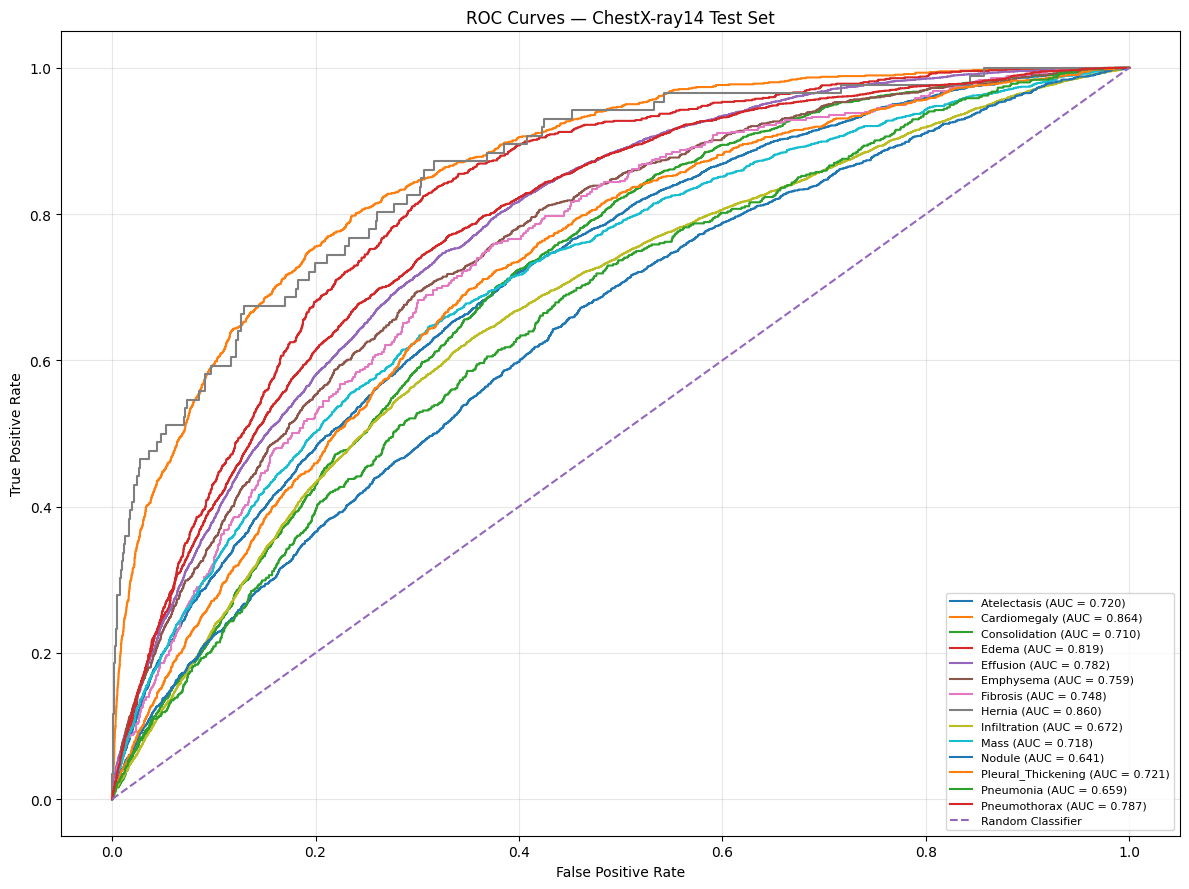

In [89]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(12, 9))

for i, disease in enumerate(DISEASES):
    fpr, tpr, _ = roc_curve(
        test_labels[:, i],
        test_probs[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{disease} (AUC = {roc_auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — ChestX-ray14 Test Set")
plt.legend(
    loc="lower right",
    fontsize=8
)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("roc_curves.png", dpi=300, bbox_inches="tight")
plt.show()

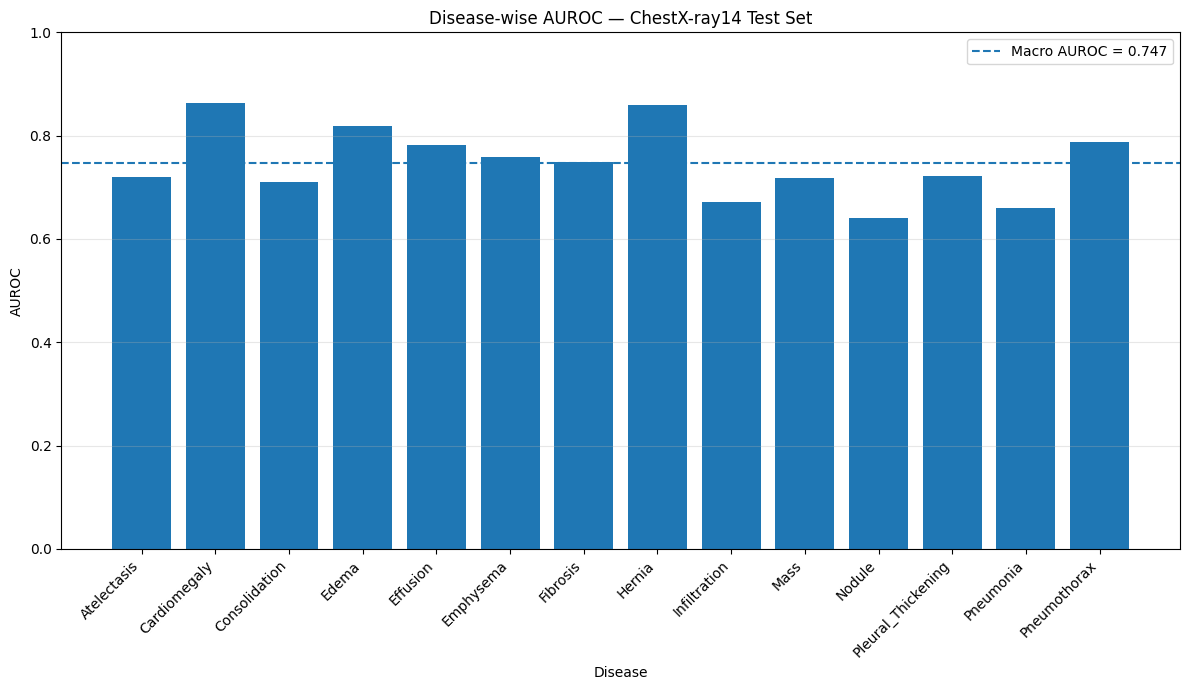

In [90]:
plt.figure(figsize=(12, 7))

plt.bar(DISEASES, test_auc_scores)

plt.axhline(
    test_macro_auc,
    linestyle="--",
    label=f"Macro AUROC = {test_macro_auc:.3f}"
)

plt.xlabel("Disease")
plt.ylabel("AUROC")
plt.title("Disease-wise AUROC — ChestX-ray14 Test Set")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("disease_auroc.png", dpi=300, bbox_inches="tight")
plt.show()

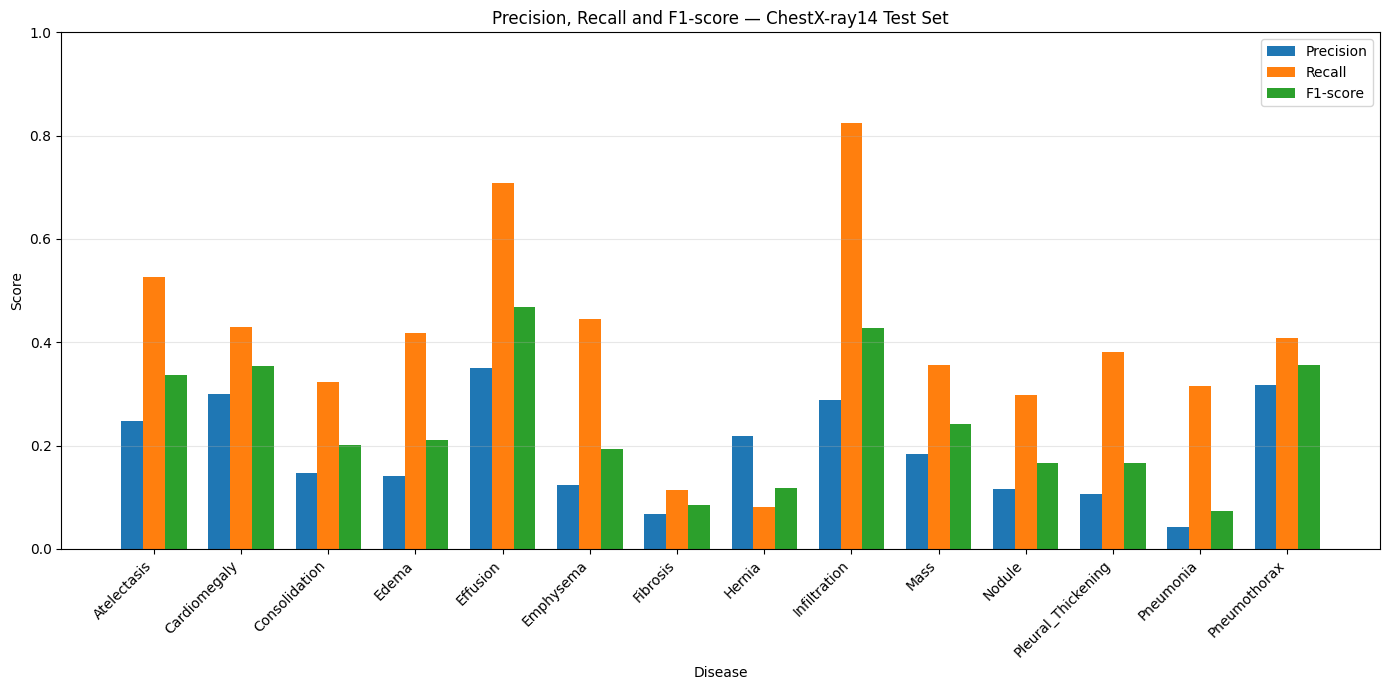

In [91]:
precision_values = [
    0.2473, 0.2999, 0.1463, 0.1405, 0.3501, 0.1242,
    0.0673, 0.2188, 0.2889, 0.1829, 0.1151, 0.1066,
    0.0418, 0.3170
]

recall_values = [
    0.5264, 0.4303, 0.3229, 0.4184, 0.7082, 0.4446,
    0.1149, 0.0814, 0.8244, 0.3564, 0.2982, 0.3806,
    0.3153, 0.4075
]

f1_values = [
    0.3366, 0.3534, 0.2014, 0.2103, 0.4686, 0.1942,
    0.0849, 0.1186, 0.4279, 0.2417, 0.1661, 0.1665,
    0.0738, 0.3566
]

x = np.arange(len(DISEASES))
width = 0.25

plt.figure(figsize=(14, 7))

plt.bar(x - width, precision_values, width, label="Precision")
plt.bar(x, recall_values, width, label="Recall")
plt.bar(x + width, f1_values, width, label="F1-score")

plt.xlabel("Disease")
plt.ylabel("Score")
plt.title("Precision, Recall and F1-score — ChestX-ray14 Test Set")

plt.xticks(
    x,
    DISEASES,
    rotation=45,
    ha="right"
)

plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("precision_recall_f1.png", dpi=300, bbox_inches="tight")
plt.show()

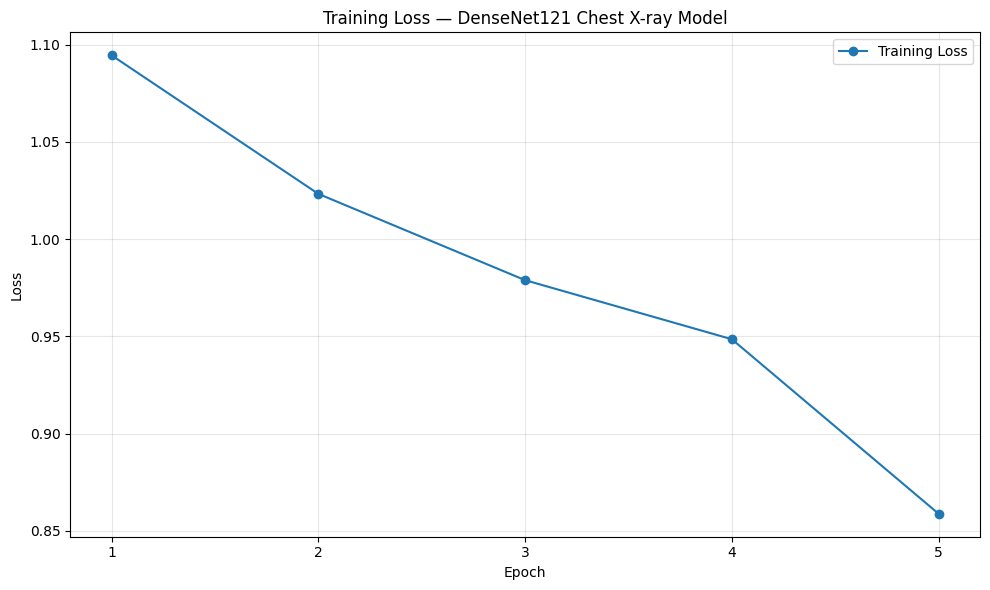

In [92]:
epochs = [1, 2, 3, 4, 5]

train_loss = [
    1.0946,
    1.0233,
    0.9789,
    0.9485,
    0.8587
]

plt.figure(figsize=(10, 6))

plt.plot(
    epochs,
    train_loss,
    marker="o",
    label="Training Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss — DenseNet121 Chest X-ray Model")

plt.xticks(epochs)
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.savefig("training_loss.png", dpi=300, bbox_inches="tight")
plt.show()

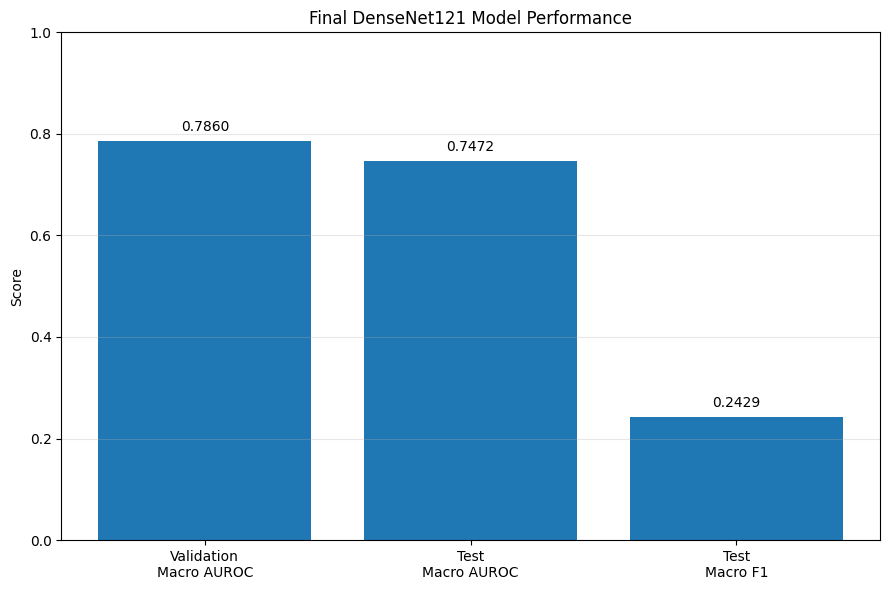

In [93]:
metrics_names = [
    "Validation\nMacro AUROC",
    "Test\nMacro AUROC",
    "Test\nMacro F1"
]

metrics_values = [
    0.7860,
    0.7472,
    0.2429
]

plt.figure(figsize=(9, 6))

bars = plt.bar(
    metrics_names,
    metrics_values
)

plt.ylabel("Score")
plt.title("Final DenseNet121 Model Performance")
plt.ylim(0, 1)

for bar, value in zip(bars, metrics_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.4f}",
        ha="center"
    )

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("final_performance.png", dpi=300, bbox_inches="tight")
plt.show()